# Práctica 2.1 · Ingeniería de características con una encuesta de hogares

Antes de entrenar un modelo hay que preparar la tabla. Este cuaderno recorre, **en el mismo orden del mazo «Ingeniería de características»**, las ocho situaciones que casi siempre aparecen en una base de datos real y aplica cada técnica con código:

1. Datos faltantes · 2. Variables categóricas · 3. Transformación de la distribución · 4. Discretización · 5. Valores atípicos · 6. Escalamiento · 7. Selección de características · 8. Creación de características

Al final se juntan todas en una sola tubería y se compara contra una línea base: **¿cuánto mejora un modelo cuando la tabla se prepara bien?**

**Datos.** `datos/2-1-ingenieria-caracteristicas.xlsx` tiene 600 hogares **simulados con fines didácticos** al estilo de una encuesta de hogares colombiana (hoja `hogares`) y un diccionario de variables (hoja `diccionario`). La variable objetivo es `pobreza_multidimensional` (1 = el hogar es pobre). La base trae a propósito los problemas que se van a resolver: celdas vacías, texto, una variable con cola larga, errores de digitación y columnas que no aportan.

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
from scipy import stats
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import (OneHotEncoder, OrdinalEncoder, LabelEncoder, PowerTransformer,
                                   StandardScaler, MinMaxScaler, RobustScaler, FunctionTransformer)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif, chi2, SequentialFeatureSelector
from sklearn.metrics import accuracy_score, roc_auc_score, mean_absolute_error
from sklearn.dummy import DummyClassifier
import warnings; warnings.filterwarnings('ignore')

DATOS = Path('datos')   # en Colab, sube la carpeta datos/ al entorno
SEMILLA = 42
pd.set_option('display.float_format', lambda v: f'{v:,.2f}')

In [2]:
# Estilo gráfico común (paleta validada para daltonismo)
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

AZUL, NARANJA, AQUA, ROJO = '#2a78d6', '#eb6834', '#1baf7a', '#e34948'
GRIS, TINTA, TINTA2 = '#898781', '#0b0b0b', '#52514e'
SEQ = LinearSegmentedColormap.from_list('azul', ['#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#0d366b'])
DIV = LinearSegmentedColormap.from_list('div', ['#1c5cab', '#86b6ef', '#f0efec', '#ee9a99', '#b02e2e'])

mpl.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': TINTA2, 'text.color': TINTA,
    'xtick.color': GRIS, 'ytick.color': GRIS, 'axes.grid': True, 'grid.color': '#e1e0d9',
    'grid.linewidth': 0.6, 'axes.spines.top': False, 'axes.spines.right': False,
    'font.size': 10, 'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'figure.dpi': 110, 'lines.linewidth': 2, 'legend.frameon': False,
})

## 0. Cargar el Excel y separar antes de transformar

`pd.read_excel` lee una hoja del libro (hace falta la librería `openpyxl`). Primero la tabla de hogares y su diccionario.

In [3]:
hogares = pd.read_excel(DATOS / '2-1-ingenieria-caracteristicas.xlsx', sheet_name='hogares')
diccionario = pd.read_excel(DATOS / '2-1-ingenieria-caracteristicas.xlsx', sheet_name='diccionario')
print(hogares.shape)
hogares.head()

(600, 19)


,id_hogar,fecha_encuesta,dia_registro,ciudad,zona,estrato,nivel_educativo_jefe,sexo_jefe,edad_jefe,personas,cuartos,menores_15,mayores_64,horas_trabajadas,ingreso_mensual,gasto_alimentos,distancia_cabecera_km,tiene_internet,pobreza_multidimensional
0,1,2025-08-24,12,Barranquilla,Urbana,3,Técnico,Hombre,78.00,2,1,0,1,36,"460,000.00",265000,1.80,Sí,0
1,2,2025-04-21,29,Medellín,Urbana,3,Técnico,Hombre,32.00,6,5,2,1,59,"1,532,000.00",880000,2.20,Sí,0
2,3,2025-04-26,31,Bucaramanga,Urbana,4,Profesional,Mujer,47.00,4,4,1,1,52,"2,574,000.00",905000,2.70,Sí,0
3,4,2025-08-12,21,Barranquilla,Urbana,2,Técnico,Mujer,30.00,4,5,2,0,32,"1,207,000.00",526000,5.00,Sí,0
4,5,2025-04-28,18,Bogotá,Urbana,2,Ninguno,Mujer,35.00,3,2,2,0,46,"829,000.00",467000,2.20,No,1


In [4]:
diccionario

,variable,descripcion,tipo,unidad o valores,situacion del mazo
0,id_hogar,Identificador del hogar en la encuesta,Entero,—,7 · variable que no aporta
1,fecha_encuesta,Fecha en que se aplicó la encuesta,Fecha,aaaa-mm-dd,8 · crear el mes; 7 · candidata
2,dia_registro,Día del mes en que se digitó el formulario,Entero,1–31,7 · variable que no aporta
3,ciudad,Ciudad del hogar,Categórica nominal,6 ciudades,1 · faltantes (moda); 2 · One-Hot y Label Enco...
4,zona,Zona del hogar,Categórica nominal (binaria),Urbana / Rural,2 · codificación
5,estrato,Estrato socioeconómico de la vivienda,Categórica ordinal (numérica),1–6,2 · un número que es ordinal
6,nivel_educativo_jefe,Máximo nivel educativo del jefe de hogar,Categórica ordinal,Ninguno < … < Posgrado,2 · codificación ordinal
7,sexo_jefe,Sexo del jefe de hogar,Categórica nominal (binaria),Hombre / Mujer,2 · codificación
8,edad_jefe,Edad del jefe de hogar,Numérica continua,años,1 · imputación; 4 · discretización; 6 · escala...
9,personas,Personas que viven en el hogar,Numérica discreta,personas,"8 · hacinamiento, ingreso per cápita"


In [5]:
hogares.info()

<class 'pandas.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   id_hogar                  600 non-null    int64         
 1   fecha_encuesta            600 non-null    datetime64[us]
 2   dia_registro              600 non-null    int64         
 3   ciudad                    582 non-null    str           
 4   zona                      600 non-null    str           
 5   estrato                   600 non-null    int64         
 6   nivel_educativo_jefe      600 non-null    str           
 7   sexo_jefe                 600 non-null    str           
 8   edad_jefe                 570 non-null    float64       
 9   personas                  600 non-null    int64         
 10  cuartos                   600 non-null    int64         
 11  menores_15                600 non-null    int64         
 12  mayores_64                600 non

La base tiene **600 hogares y 19 columnas**. `info()` ya deja ver tres de los problemas del mazo: `ciudad` tiene 582 valores de 600, `edad_jefe` 570 e `ingreso_mensual` 564 (**datos faltantes**), y cinco columnas son texto (`str`): ciudad, zona, nivel educativo, sexo e internet (**variables categóricas**). La fecha llegó como fecha (`datetime64`), lista para crear variables con ella.

Toda técnica que «aprende» algo de los datos (una media para imputar, los límites de un recorte, el mínimo y el máximo de un escalamiento) se ajusta **solo con entrenamiento** y luego se aplica a prueba. Si se calcula con la tabla completa, la prueba deja de ser nueva: es la fuga de información de la lámina «Cuidado con la información del futuro». Por eso se separa ahora, estratificando por la variable objetivo.

In [6]:
Y = 'pobreza_multidimensional'
train, test = train_test_split(hogares, test_size=0.2, stratify=hogares[Y], random_state=SEMILLA)
train, test = train.copy(), test.copy()
print(f'Entrenamiento: {len(train)} hogares · Prueba: {len(test)} hogares')
print(f'Pobreza: {train[Y].mean():.1%} en entrenamiento y {test[Y].mean():.1%} en prueba')

Entrenamiento: 480 hogares · Prueba: 120 hogares
Pobreza: 30.0% en entrenamiento y 30.0% en prueba


Quedan **480 hogares para entrenar y 120 para probar**, los dos con la misma tasa de pobreza (30,0 %) gracias a la estratificación. Desde aquí, todo lo que se calcule (medianas, límites, escalas) sale de los 480 de entrenamiento.

## 1. Manejo de datos faltantes

**Problema:** celdas incompletas. **Técnicas:** descarte (eliminación) e imputación (media, mediana, moda, vecinos más cercanos).

In [7]:
faltan = hogares.isna().sum()
faltan = faltan[faltan > 0].to_frame('faltantes')
faltan['porcentaje'] = faltan['faltantes'] / len(hogares) * 100
faltan

,faltantes,porcentaje
ciudad,18,3.00
edad_jefe,30,5.00
ingreso_mensual,36,6.00


Faltan **18 ciudades (3,0 %), 30 edades (5,0 %) y 36 ingresos (6,0 %)**. Ninguna columna pierde mucho por sí sola, pero los vacíos están en filas distintas, y eso pesa cuando se decide descartar.

### 1.1 Descarte

Se eliminan las filas con alguna celda vacía.

In [8]:
sin_faltantes = train.dropna()
perdidas = len(train) - len(sin_faltantes)
print(f'Quedan {len(sin_faltantes)} de {len(train)} hogares: se pierde el {perdidas / len(train):.1%} de la muestra')
print(f'Tasa de pobreza: {train[Y].mean():.1%} antes y {sin_faltantes[Y].mean():.1%} después del descarte')

Quedan 416 de 480 hogares: se pierde el 13.3% de la muestra
Tasa de pobreza: 30.0% antes y 29.3% después del descarte


**Descartar cuesta caro:** quedan 416 de 480 hogares, es decir, se pierde el 13,3 % de la muestra por culpa de columnas a las que les falta como máximo el 6 %. Aquí la tasa de pobreza casi no cambia (30,0 % → 29,3 %) porque los vacíos se pusieron al azar; si faltaran justo en los hogares más pobres, el descarte sesgaría el resultado. Por eso el descarte solo conviene con pocos faltantes y al azar.

### 1.2 Imputación por media y por mediana

`SimpleImputer` calcula el valor de reemplazo con entrenamiento (`fit`) y lo aplica (`transform`).

In [9]:
num_falt = ['edad_jefe', 'ingreso_mensual']
valores = {}
for estrategia, nombre in [('mean', 'media'), ('median', 'mediana')]:
    imp = SimpleImputer(strategy=estrategia).fit(train[num_falt])
    valores[nombre] = pd.Series(imp.statistics_, index=num_falt)
pd.DataFrame(valores)

,media,mediana
edad_jefe,45.39,47.00
ingreso_mensual,"1,597,321.59","1,194,000.00"


En la edad, media (45,4) y mediana (47,0) casi coinciden: la distribución es bastante simétrica y cualquiera sirve. En el ingreso no: **la media es 1.597.322 pesos y la mediana 1.194.000**. La media queda inflada por unos pocos ingresos muy altos (y por errores de digitación que se verán en la situación 5).

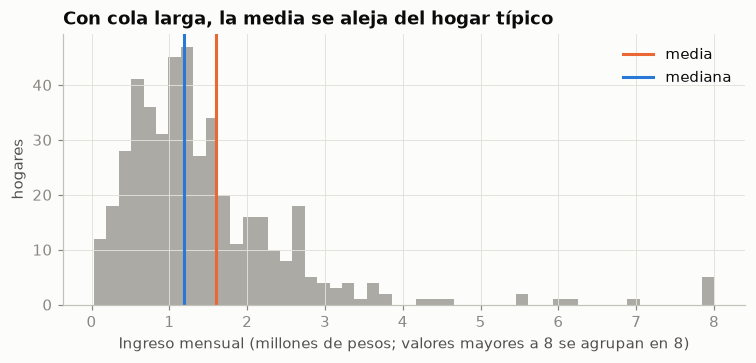

In [10]:
fig, ax = plt.subplots(figsize=(8, 3.2))
ing = train['ingreso_mensual'].dropna() / 1e6
ax.hist(ing.clip(upper=8), bins=50, color=GRIS, alpha=.7)
ax.axvline(valores['media']['ingreso_mensual'] / 1e6, color=NARANJA, label='media')
ax.axvline(valores['mediana']['ingreso_mensual'] / 1e6, color=AZUL, label='mediana')
ax.set_xlabel('Ingreso mensual (millones de pesos; valores mayores a 8 se agrupan en 8)')
ax.set_ylabel('hogares'); ax.set_title('Con cola larga, la media se aleja del hogar típico'); ax.legend()
plt.show()

El histograma lo muestra: el ingreso tiene la mayoría de hogares por debajo de dos millones y una cola larga a la derecha. **La mediana cae en el centro del hogar típico; la media se corre hacia la cola.** Para imputar una variable así, la mediana es la elección segura.

### 1.3 Imputación por moda (categórica) y por vecinos más cercanos (KNN)

En una variable de texto no hay media: se usa la categoría más frecuente. KNN, en cambio, busca los 5 hogares más parecidos en otras variables y promedia su valor. Como mide distancias, **hay que escalar antes** (situación 6).

In [11]:
imp_moda = SimpleImputer(strategy='most_frequent').fit(train[['ciudad']])
print('Moda de ciudad:', imp_moda.statistics_[0])

vecinos = ['edad_jefe', 'ingreso_mensual', 'personas', 'cuartos', 'horas_trabajadas', 'estrato', 'gasto_alimentos']
esc = StandardScaler().fit(train[vecinos])                     # ignora los NaN al ajustar
knn = KNNImputer(n_neighbors=5).fit(esc.transform(train[vecinos]))
knn_train = pd.DataFrame(esc.inverse_transform(knn.transform(esc.transform(train[vecinos]))),
                         columns=vecinos, index=train.index)
falta_ing = train['ingreso_mensual'].isna()
imputados = knn_train.loc[falta_ing, 'ingreso_mensual']
print(f'KNN imputó {falta_ing.sum()} ingresos distintos entre sí: de {imputados.min():,.0f} a {imputados.max():,.0f} pesos')
print(f'(la mediana habría puesto {valores["mediana"]["ingreso_mensual"]:,.0f} en todos)')

Moda de ciudad: Bogotá
KNN imputó 26 ingresos distintos entre sí: de 166,200 a 9,534,000 pesos
(la mediana habría puesto 1,194,000 en todos)


La moda de `ciudad` es **Bogotá**, y es lo que se pondrá en las 18 ciudades vacías. KNN, en cambio, no pone un solo valor: imputó los 26 ingresos faltantes de entrenamiento con valores **distintos entre sí, de 166.200 a 9.534.000 pesos**, según cuánto gana cada hogar parecido (en edad, personas, horas, estrato y gasto). Es más fino que la mediana (1.194.000 para todos), pero depende de que haya variables relacionadas y de escalarlas antes.

## 2. Codificación de variables categóricas

**Problema:** columnas con texto que el modelo no puede operar. **Técnicas:** One-Hot y Label Encoding (nominales); Label Encoding con orden (ordinales).

### 2.1 One-Hot en una nominal: `ciudad`

In [12]:
ciudad_train = train[['ciudad']].fillna(imp_moda.statistics_[0])
ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore').fit(ciudad_train)
pd.DataFrame(ohe.transform(ciudad_train.head()).astype(int), columns=ohe.get_feature_names_out(),
             index=ciudad_train.index[:5]).join(ciudad_train.head())

,ciudad_Barranquilla,ciudad_Bogotá,ciudad_Bucaramanga,ciudad_Cali,ciudad_Medellín,ciudad_Tunja,ciudad
269,0,1,0,0,0,0,Bogotá
501,0,0,1,0,0,0,Bucaramanga
401,0,0,0,0,0,1,Tunja
138,1,0,0,0,0,0,Barranquilla
359,0,0,0,1,0,0,Cali


One-Hot convierte `ciudad` en **seis columnas de ceros y unos**, una por ciudad: el hogar 269 es de Bogotá y solo tiene un 1 en `ciudad_Bogotá`. Ninguna ciudad «vale más» que otra. El costo es el ancho de la tabla: con seis ciudades no importa; con 1.100 municipios serían 1.100 columnas.

### 2.2 Label Encoding en una nominal: el orden que no existe

In [13]:
le = LabelEncoder().fit(ciudad_train['ciudad'])
pd.Series(range(len(le.classes_)), index=le.classes_, name='código asignado')

Barranquilla    0
Bogotá          1
Bucaramanga     2
Cali            3
Medellín        4
Tunja           5
Name: código asignado, dtype: int64

Label Encoding asigna números por orden alfabético: **Barranquilla 0, Bogotá 1, … Tunja 5**. Un modelo lineal leería que Tunja «es cinco veces» Bogotá y que Cali está «entre» Bucaramanga y Medellín. Ese orden no existe. Solo es aceptable en modelos de árboles, que cortan por umbrales y no usan la magnitud.

### 2.3 Label Encoding con orden en una ordinal: `nivel_educativo_jefe`

`OrdinalEncoder` recibe el orden explícito; si no se le da, ordena alfabéticamente.

In [14]:
orden_edu = ['Ninguno', 'Primaria', 'Bachiller', 'Técnico', 'Profesional', 'Posgrado']
oe = OrdinalEncoder(categories=[orden_edu]).fit(train[['nivel_educativo_jefe']])
tabla = train.groupby('nivel_educativo_jefe')[Y].agg(hogares='size', tasa_pobreza='mean').reindex(orden_edu)
tabla['código'] = oe.transform(pd.DataFrame({'nivel_educativo_jefe': orden_edu})).ravel().astype(int)
tabla

,hogares,tasa_pobreza,código
nivel_educativo_jefe,,,
Ninguno,23,0.78,0
Primaria,98,0.50,1
Bachiller,173,0.31,2
Técnico,71,0.23,3
Profesional,88,0.09,4
Posgrado,27,0.00,5


Aquí el orden sí existe y el código lo respeta: **Ninguno 0 < Primaria 1 < … < Posgrado 5**. Además, la tasa de pobreza baja de forma ordenada: 78 % sin educación, 50 % con primaria, 31 % con bachillerato y 0 % con posgrado. Un solo número capta esa escalera, que es justo lo que se busca en una ordinal.

## 3. Transformación de la distribución

**Problema:** variables asimétricas. **Técnica:** aplicar una función a cada valor: raíz, logaritmo, Box-Cox o Yeo-Johnson. La asimetría (*skewness*) vale 0 en una distribución simétrica.

In [15]:
x = train['ingreso_mensual'].dropna()
x = x[x > 0]
bc = PowerTransformer(method='box-cox', standardize=False).fit(x.to_frame())
yj = PowerTransformer(method='yeo-johnson', standardize=False).fit(x.to_frame())
versiones = {'original': x.values, 'raíz cuadrada': np.sqrt(x.values), 'logaritmo': np.log1p(x.values),
             'Box-Cox': bc.transform(x.to_frame()).ravel(), 'Yeo-Johnson': yj.transform(x.to_frame()).ravel()}
pd.DataFrame({'asimetría': {k: stats.skew(v) for k, v in versiones.items()},
              'λ estimado': {'Box-Cox': bc.lambdas_[0], 'Yeo-Johnson': yj.lambdas_[0]}})

,asimetría,λ estimado
original,8.55,NaN
raíz cuadrada,3.31,NaN
logaritmo,-0.43,NaN
Box-Cox,0.07,0.09
Yeo-Johnson,0.07,0.09


El ingreso original tiene una **asimetría de 8,55** (una simétrica tiene 0). La raíz la baja a 3,31, pero no basta. El logaritmo la lleva a −0,43, ya cerca de la campana. **Box-Cox y Yeo-Johnson la dejan en 0,07**: buscan el exponente que mejor simetriza, y aquí eligieron λ = 0,09, casi un logaritmo (λ = 0 es exactamente el logaritmo).

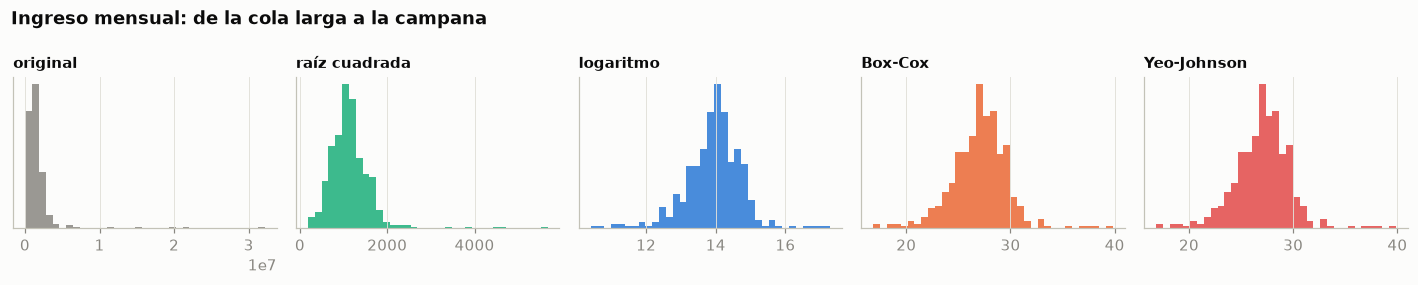

In [16]:
fig, axs = plt.subplots(1, 5, figsize=(13, 2.6))
for ax, (nombre, v), color in zip(axs, versiones.items(), [GRIS, AQUA, AZUL, NARANJA, ROJO]):
    ax.hist(v, bins=35, color=color, alpha=.85); ax.set_title(nombre, fontsize=10); ax.set_yticks([])
plt.suptitle('Ingreso mensual: de la cola larga a la campana', x=.01, ha='left', fontweight='bold')
plt.tight_layout(); plt.show()

Los cinco histogramas cuentan la misma historia: de una barra alta pegada a la izquierda (original) a una forma de campana (log, Box-Cox, Yeo-Johnson). Para el modelo final se usará `log1p`: da casi lo mismo que Box-Cox y se explica en una frase («cada unidad es un aumento porcentual»).

## 4. Discretización de variables numéricas

**Problema:** una variable continua con demasiado detalle. **Técnica:** agrupar en intervalos por criterio del dominio, por ancho igual o por frecuencia igual (cuantiles). Se aplica a la edad del jefe de hogar.

In [17]:
edad = train['edad_jefe'].dropna()
grupos = {
    'Dominio (etapas de la vida)': pd.cut(edad, bins=[17, 29, 44, 59, 120], labels=['18–29', '30–44', '45–59', '60 y más']),
    'Ancho igual (4 tramos)': pd.cut(edad, bins=4),
    'Frecuencia igual (cuartiles)': pd.qcut(edad, q=4),
}
for nombre, g in grupos.items():
    print(nombre); print(g.value_counts(sort=False).to_string()); print()

Dominio (etapas de la vida)
edad_jefe
18–29        59
30–44       137
45–59       194
60 y más     63

Ancho igual (4 tramos)
edad_jefe
(17.933, 34.75]     95
(34.75, 51.5]      207
(51.5, 68.25]      135
(68.25, 85.0]       16

Frecuencia igual (cuartiles)
edad_jefe
(17.999, 36.0]    115
(36.0, 47.0]      132
(47.0, 54.0]       95
(54.0, 85.0]      111



Las tres reglas reparten las mismas 453 edades de forma muy distinta. **Por dominio**, los grupos tienen sentido (jóvenes, adultos, adultos mayores) aunque queden desiguales (59 a 194 hogares). **Por ancho igual**, el último tramo (68 a 85 años) se queda con solo 16 hogares: muy poco para concluir algo. **Por cuartiles**, todos quedan parecidos (95 a 132), pero los cortes (36, 47, 54 años) no significan nada fuera de esta muestra.

In [18]:
dominio = grupos['Dominio (etapas de la vida)']
train.loc[dominio.index].groupby(dominio, observed=True)[Y].mean().rename('tasa de pobreza').to_frame()

,tasa de pobreza
edad_jefe,
18–29,0.17
30–44,0.31
45–59,0.35
60 y más,0.24


Con los grupos de dominio aparece algo que la edad continua escondía: **la pobreza no crece en línea con la edad**. Es baja en jefes jóvenes (17 %), sube hasta 35 % entre 45 y 59 años y baja otra vez a 24 % después de los 60. Un modelo lineal con la edad como número no vería esa forma de joroba; con los grupos, sí.

## 5. Manejo de valores atípicos

**Problema:** valores extremos que distorsionan. **Técnicas:** eliminación, recorte (capping), evaluación comparativa y preservación. Primero, ¿cuáles son atípicos? La regla del rango intercuartil (IQR) marca lo que cae por fuera de Q1 − 1,5·IQR y Q3 + 1,5·IQR.

In [19]:
def limites_iqr(s):
    q1, q3 = s.quantile([.25, .75]); r = q3 - q1
    return q1 - 1.5 * r, q3 + 1.5 * r

ing = train['ingreso_mensual']
inf, sup = limites_iqr(ing)
inf_log, sup_log = limites_iqr(np.log(ing))
print(f'Escala original: límite superior {sup:,.0f} pesos → {(ing > sup).sum()} atípicos')
print(f'Escala logarítmica: límite superior {np.exp(sup_log):,.0f} pesos → {(np.log(ing) > sup_log).sum()} atípicos')

Escala original: límite superior 3,338,375 pesos → 21 atípicos
Escala logarítmica: límite superior 6,536,364 pesos → 6 atípicos


La misma regla da resultados muy distintos según la escala. En pesos, el límite superior es 3.338.375 y marca **21 «atípicos»**, pero muchos son simplemente hogares de ingreso alto, normales en una variable con cola larga. Sobre el logaritmo (situación 3), el límite sube a 6.536.364 y quedan **6**. Lección: en una variable sesgada, se transforma primero y se buscan atípicos después.

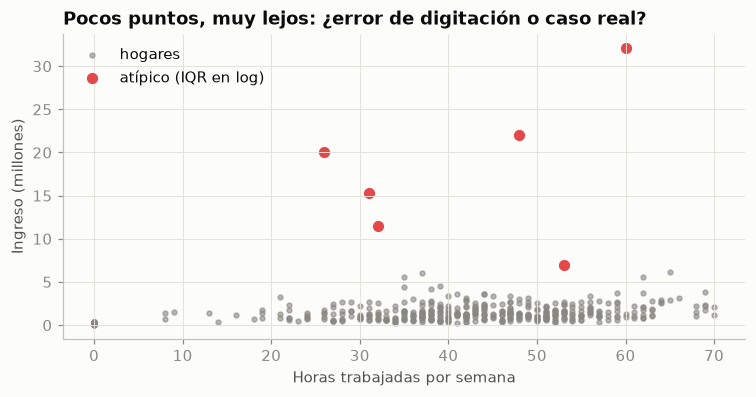

,horas_trabajadas,nivel_educativo_jefe,ingreso_mensual,gasto_alimentos
389,32,Primaria,"11,460,000.00",555000
178,26,Técnico,"20,090,000.00",1231000
572,48,Técnico,"22,050,000.00",848000
146,60,Bachiller,"32,160,000.00",1272000
340,53,Profesional,"7,001,000.00",2856000
256,31,Bachiller,"15,260,000.00",523000


In [20]:
atipico = np.log(ing) > sup_log
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.scatter(train['horas_trabajadas'], ing / 1e6, s=10, color=GRIS, alpha=.6, label='hogares')
ax.scatter(train.loc[atipico, 'horas_trabajadas'], ing[atipico] / 1e6, s=40, color=ROJO, label='atípico (IQR en log)')
ax.set_xlabel('Horas trabajadas por semana'); ax.set_ylabel('Ingreso (millones)')
ax.set_title('Pocos puntos, muy lejos: ¿error de digitación o caso real?'); ax.legend()
plt.show()
train.loc[atipico, ['horas_trabajadas', 'nivel_educativo_jefe', 'ingreso_mensual', 'gasto_alimentos']]

El gráfico y la tabla muestran los seis. Cinco son errores evidentes de digitación: ingresos de 11 a 32 millones con un gasto en alimentos corriente (de 523.000 a 1.272.000) y horas normales. A todos les sobra un cero. El sexto (7.001.000 pesos, jefe profesional, gasto de 2.856.000) es coherente con su gasto: **parece un hogar real de ingreso alto**. Ningún método automático distingue estos dos casos; hay que mirarlos.

### 5.1 Eliminación, recorte y evaluación comparativa

Se ajusta la misma regresión (ingreso según horas y educación) con tres versiones de los datos de entrenamiento y se mide el error absoluto medio en los hogares de **prueba** que no son atípicos.

In [21]:
def xy(d):
    d = d.dropna(subset=['ingreso_mensual'])
    X = np.column_stack([d['horas_trabajadas'], oe.transform(d[['nivel_educativo_jefe']]).ravel()])
    return X, d['ingreso_mensual'].values

base = train.dropna(subset=['ingreso_mensual'])
mascara = np.log(base['ingreso_mensual']) > sup_log
versiones_atip = {
    'Con atípicos': base,
    'Eliminación': base[~mascara],
    'Recorte (capping)': base.assign(ingreso_mensual=base['ingreso_mensual'].clip(upper=np.exp(sup_log))),
}
prueba = test.dropna(subset=['ingreso_mensual'])
prueba = prueba[np.log(prueba['ingreso_mensual']) <= sup_log]
Xp, yp = xy(prueba)
res = {}
for nombre, d in versiones_atip.items():
    m = LinearRegression().fit(*xy(d))
    res[nombre] = {'pendiente por hora (pesos)': m.coef_[0], 'error absoluto medio en prueba (pesos)': mean_absolute_error(yp, m.predict(Xp))}
pd.DataFrame(res).T

,pendiente por hora (pesos),error absoluto medio en prueba (pesos)
Con atípicos,"25,599.40","616,366.73"
Eliminación,"22,840.01","579,138.16"
Recorte (capping),"22,920.16","587,307.58"


Los atípicos sí cambian el modelo. Con ellos, cada hora trabajada «vale» **25.599 pesos**; sin ellos, 22.840, y con recorte, 22.920. En los hogares de prueba, el error absoluto medio baja de **616.367 pesos (con atípicos) a 579.138 (eliminación) y 587.308 (recorte)**. Aquí gana la eliminación porque casi todos los atípicos son errores; si fueran reales, el recorte, que conserva la fila, sería la opción más prudente.

### 5.2 Preservación

Si el atípico puede ser la señal (por ejemplo, para detectar errores o fraudes), no se borra: se marca con una variable nueva.

In [22]:
train['ingreso_atipico'] = (np.log(train['ingreso_mensual']) > sup_log).astype(int)
test['ingreso_atipico'] = (np.log(test['ingreso_mensual']) > sup_log).astype(int)   # mismo límite, calculado en entrenamiento
train['ingreso_atipico'].value_counts()

ingreso_atipico
0    474
1      6
Name: count, dtype: int64

Preservar no borra nada: crea `ingreso_atipico`, que vale 1 en **6 de los 480 hogares**. Sirve si el objetivo es justamente encontrar esos casos (auditar la encuesta, detectar fraude) o si se quiere que el modelo sepa que esa cifra es dudosa.

## 6. Escalamiento de datos

**Problema:** variables en rangos muy distintos (años, pesos, kilómetros, personas). **Técnicas:** estandarización, Min-Max en [0, 1] o en [−1, 1] y escalamiento por rango intercuartil.

In [23]:
cols = ['edad_jefe', 'ingreso_mensual', 'distancia_cabecera_km', 'personas']
base_esc = SimpleImputer(strategy='median').fit(train[cols]).transform(train[cols])
escaladores = {'Original': None, 'Estandarización': StandardScaler(), 'Min-Max [0, 1]': MinMaxScaler(),
               'Min-Max [−1, 1]': MinMaxScaler((-1, 1)), 'Rango intercuartil': RobustScaler()}
filas = []
for nombre, e in escaladores.items():
    z = base_esc if e is None else e.fit_transform(base_esc)
    for j, c in enumerate(cols):
        filas.append({'escalamiento': nombre, 'variable': c, 'mínimo': z[:, j].min(),
                      'mediana': np.median(z[:, j]), 'máximo': z[:, j].max(), 'desviación': z[:, j].std()})
pd.DataFrame(filas).set_index(['escalamiento', 'variable'])

mínimo      mediana        máximo  \
escalamiento       variable                                                     
Original           edad_jefe                 18.00        47.00         85.00   
                   ingreso_mensual       33,000.00 1,194,000.00 32,160,000.00   
                   distancia_cabecera_km      0.10         3.00         60.00   
                   personas                   1.00         4.00         10.00   
Estandarización    edad_jefe                 -2.08         0.11          2.99   
                   ingreso_mensual           -0.69        -0.17         13.64   
                   distancia_cabecera_km     -0.66        -0.43          4.04   
                   personas                  -1.63         0.03          3.35   
Min-Max [0, 1]     edad_jefe                  0.00         0.43          1.00   
                   ingreso_mensual            0.00         0.04          1.00   
                   distancia_cabecera_km      0.00         0.05          1.00   
                   personas                   0.00         0.33          1.00   
Min-Max [−1, 1]    edad_jefe                 -1.00        -0.13          1.00   
                   ingreso_mensual           -1.00        -0.93          1.00   
                   distancia_cabecera_km     -1.00        -0.90          1.00   
                   personas                  -1.00        -0.33          1.00   
Rango intercuartil edad_jefe                 -1.71         0.00          2.24   
                   ingreso_mensual           -1.22         0.00         32.59   
                   distancia_cabecera_km     -0.38         0.00          7.40   
                   personas                  -1.50         0.00          3.00   

                                           desviación  
escalamiento       variable                            
Original           edad_jefe                    13.21  
                   ingreso_mensual       2,241,547.93  
                   distancia_cabecera_km        12.76  
                   personas                      1.81  
Estandarización    edad_jefe                     1.00  
                   ingreso_mensual               1.00  
                   distancia_cabecera_km         1.00  
                   personas                      1.00  
Min-Max [0, 1]     edad_jefe                     0.20  
                   ingreso_mensual               0.07  
                   distancia_cabecera_km         0.21  
                   personas                      0.20  
Min-Max [−1, 1]    edad_jefe                     0.39  
                   ingreso_mensual               0.14  
                   distancia_cabecera_km         0.43  
                   personas                      0.40  
Rango intercuartil edad_jefe                     0.78  
                   ingreso_mensual               2.36  
                   distancia_cabecera_km         1.66  
                   personas                      0.90

En la escala original, el ingreso llega a **32.160.000** y las personas a 10: cualquier método basado en distancias solo «vería» el ingreso. La estandarización deja todas con desviación 1, pero el ingreso sigue llegando a 13,64 por culpa del error de 32 millones. **Min-Max muestra el problema del atípico:** en [0, 1], la mediana del ingreso queda en 0,04 (en [−1, 1], en −0,93), es decir, casi todos los hogares aplastados contra el mínimo. **El rango intercuartil** centra en la mediana y no se deja arrastrar: el hogar típico queda en 0 y solo el error se dispara (32,59).

## 7. Selección de características

**Problema:** muchas columnas; no todas aportan. **Técnicas:** filtrado, wrapper y embebidos. Para comparar se arma primero una tabla numérica con las candidatas, imputada y codificada con lo visto hasta aquí (todo ajustado con entrenamiento).

In [24]:
num_cand = ['id_hogar', 'dia_registro', 'estrato', 'edad_jefe', 'personas', 'cuartos', 'menores_15', 'mayores_64',
            'horas_trabajadas', 'ingreso_mensual', 'gasto_alimentos', 'distancia_cabecera_km']
imp_num = SimpleImputer(strategy='median').fit(train[num_cand])

def tabla_candidatas(d):
    X = pd.DataFrame(imp_num.transform(d[num_cand]), columns=num_cand, index=d.index)
    X['ingreso_mensual'] = np.log1p(X['ingreso_mensual']); X['gasto_alimentos'] = np.log1p(X['gasto_alimentos'])
    X['educacion'] = oe.transform(d[['nivel_educativo_jefe']]).ravel()
    X['rural'] = (d['zona'] == 'Rural').astype(int)
    X['sin_internet'] = (d['tiene_internet'] == 'No').astype(int)
    X['mujer'] = (d['sexo_jefe'] == 'Mujer').astype(int)
    return X

Xtr, Xte = tabla_candidatas(train), tabla_candidatas(test)
ytr, yte = train[Y].values, test[Y].values
print(Xtr.shape[1], 'candidatas:', ', '.join(Xtr.columns))

16 candidatas: id_hogar, dia_registro, estrato, edad_jefe, personas, cuartos, menores_15, mayores_64, horas_trabajadas, ingreso_mensual, gasto_alimentos, distancia_cabecera_km, educacion, rural, sin_internet, mujer


Hay **16 candidatas**: las 12 numéricas (incluidas `id_hogar` y `dia_registro`, que no deberían aportar nada) y 4 construidas con lo visto: educación ordinal, rural, sin internet y jefe mujer. El ingreso y el gasto ya entran en logaritmo.

### 7.1 Filtrado: un puntaje por variable, sin modelo

In [25]:
mi = pd.Series(mutual_info_classif(Xtr, ytr, random_state=SEMILLA), index=Xtr.columns)
chi = pd.Series(chi2(MinMaxScaler().fit_transform(Xtr), ytr)[0], index=Xtr.columns)   # χ² exige valores no negativos
filtro = pd.DataFrame({'información mutua': mi, 'χ²': chi}).sort_values('información mutua', ascending=False)
filtro

,información mutua,χ²
ingreso_mensual,0.12,2.49
rural,0.08,57.57
estrato,0.08,9.13
gasto_alimentos,0.07,2.39
educacion,0.07,9.75
personas,0.06,4.35
sin_internet,0.05,52.94
menores_15,0.04,5.94
horas_trabajadas,0.03,3.40
distancia_cabecera_km,0.03,9.51


Las dos medidas de filtro coinciden en lo esencial. Por **información mutua**, arriba quedan el ingreso (0,12), la zona rural (0,08), el estrato (0,08), el gasto y la educación (0,07). Abajo, en 0,00, `id_hogar`, `dia_registro` y `mayores_64`. **χ²** ordena distinto (rural 57,6 y sin internet 52,9 lideran, porque premia las binarias) y también deja al final `id_hogar` (0,00) y `dia_registro` (0,26). El filtro es rápido y descarta lo obvio, pero mira cada variable sola.

### 7.2 Wrapper: el modelo prueba subconjuntos

Selección hacia adelante: arranca vacío y en cada ronda agrega la variable que más sube el AUC en validación cruzada; se detiene cuando ninguna mejora más de 0,005.

In [26]:
logit = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
sfs = SequentialFeatureSelector(logit, direction='forward', n_features_to_select='auto', tol=0.005,
                                scoring='roc_auc', cv=StratifiedKFold(5, shuffle=True, random_state=SEMILLA)).fit(Xtr, ytr)
wrapper = list(Xtr.columns[sfs.get_support()])
print(f'El wrapper conservó {len(wrapper)} variables:', ', '.join(wrapper))

El wrapper conservó 6 variables: estrato, personas, menores_15, mayores_64, ingreso_mensual, sin_internet


El wrapper se quedó con **6 de 16 variables**: estrato, personas, menores de 15, mayores de 64, ingreso y sin internet. Llama la atención que tome menores y mayores, que por separado puntuaban bajo en el filtro: juntos con personas, le dan al modelo la estructura del hogar. El wrapper ve combinaciones; el filtro no. Su costo es entrenar el modelo muchas veces.

### 7.3 Embebidos: la selección ocurre al entrenar

La regresión logística con penalización L1 (Lasso) lleva a cero los coeficientes de lo que no aporta; el random forest reparte una importancia entre las variables.

In [27]:
l1 = make_pipeline(StandardScaler(), LogisticRegression(penalty='l1', solver='liblinear', C=0.05)).fit(Xtr, ytr)
rf = RandomForestClassifier(n_estimators=300, random_state=SEMILLA).fit(Xtr, ytr)
emb = pd.DataFrame({'coeficiente L1': l1[-1].coef_[0], 'importancia RF': rf.feature_importances_}, index=Xtr.columns)
emb['sale con L1'] = np.where(emb['coeficiente L1'] == 0, 'sí', '')
emb.sort_values('importancia RF', ascending=False)

,coeficiente L1,importancia RF,sale con L1
ingreso_mensual,-0.79,0.19,
gasto_alimentos,0.00,0.08,sí
sin_internet,0.47,0.07,
distancia_cabecera_km,0.00,0.07,sí
horas_trabajadas,-0.08,0.07,
personas,0.26,0.07,
educacion,-0.28,0.07,
rural,0.22,0.06,
menores_15,0.30,0.06,
id_hogar,0.00,0.05,sí


La penalización L1 dejó en cero **7 variables**: gasto, distancia, `id_hogar`, edad, `dia_registro`, cuartos y jefe mujer; conserva el ingreso (−0,79, el más fuerte), sin internet (0,47) y menores (0,30). El random forest también da importancia baja a `dia_registro` (0,04), pero **le asigna 0,05 a `id_hogar`**, más que a mayores de 64 (0,02). Las importancias de un bosque nunca son exactamente cero y pueden premiar el ruido: hay que leerlas con cuidado.

## 8. Creación de características

**Problema:** la información útil está repartida entre varias columnas. **Técnica:** combinarlas en una variable con sentido en el dominio. Las mismas que muestra el mazo: ingreso per cápita, hacinamiento (personas ÷ cuartos) y tasa de dependencia, más el mes a partir de la fecha.

In [28]:
def crear(d):
    d = d.copy()
    d['ingreso_per_capita'] = d['ingreso_mensual'] / d['personas']
    d['hacinamiento'] = d['personas'] / d['cuartos']
    activos = (d['personas'] - d['menores_15'] - d['mayores_64']).clip(lower=1)
    d['tasa_dependencia'] = (d['menores_15'] + d['mayores_64']) / activos
    d['mes_encuesta'] = pd.to_datetime(d['fecha_encuesta']).dt.month
    return d

train, test = crear(train), crear(test)
categoria = pd.cut(train['hacinamiento'], bins=[0, 2, 3, np.inf], right=False, labels=['Sin hacinamiento', 'Mitigable', 'Crítico'])
train.groupby(categoria, observed=True)[Y].agg(hogares='size', tasa_pobreza='mean')

,hogares,tasa_pobreza
hacinamiento,,
Sin hacinamiento,342,0.27
Mitigable,110,0.29
Crítico,28,0.75


El hacinamiento separa los hogares: con menos de 2 personas por cuarto la pobreza es 27 %; entre 2 y 3, 29 %, y **con 3 o más (crítico), 75 %**. Ni `personas` ni `cuartos` por separado muestran ese salto. Es la combinación la que lleva la señal.

In [29]:
nuevas = ['ingreso_per_capita', 'hacinamiento', 'tasa_dependencia', 'mes_encuesta']
X_nuevas = SimpleImputer(strategy='median').fit_transform(train[nuevas])
pd.Series(mutual_info_classif(X_nuevas, ytr, random_state=SEMILLA), index=nuevas, name='información mutua').sort_values(ascending=False).to_frame()

,información mutua
ingreso_per_capita,0.17
hacinamiento,0.07
mes_encuesta,0.03
tasa_dependencia,0.02


Entre las variables nuevas, **el ingreso per cápita alcanza una información mutua de 0,17**, más que cualquier variable original (el ingreso total tenía 0,12): dividir por personas convierte el ingreso del hogar en el ingreso de cada miembro. El hacinamiento (0,07) también aporta. El mes (0,03) y la tasa de dependencia (0,02) aportan poco; el valor del mes es ruido de la estimación (la fecha no tiene relación con la pobreza en estos datos).

## 9. Todo junto: una tubería y su comparación con la línea base

Se arman tres modelos y se evalúan con los 120 hogares de prueba, que no se han usado para nada:

- **Línea base 1:** decir siempre la clase más frecuente («no pobre»).
- **Línea base 2:** regresión logística con las columnas numéricas tal como vienen (solo se imputa la mediana para que el modelo corra).
- **Tubería completa:** las técnicas elegidas en cada situación y las variables creadas, dentro de un `ColumnTransformer` que se ajusta solo con entrenamiento.

In [30]:
numericas_crudas = ['estrato', 'edad_jefe', 'personas', 'cuartos', 'menores_15', 'mayores_64', 'horas_trabajadas',
                    'ingreso_mensual', 'gasto_alimentos', 'distancia_cabecera_km']
base2 = make_pipeline(SimpleImputer(strategy='median'), LogisticRegression(max_iter=2000))

log_escala = make_pipeline(SimpleImputer(strategy='median'), FunctionTransformer(np.log1p), StandardScaler())
robusta = make_pipeline(SimpleImputer(strategy='median'), RobustScaler())
preparacion = ColumnTransformer([
    ('cola_larga', log_escala, ['ingreso_mensual', 'gasto_alimentos', 'ingreso_per_capita']),
    ('numericas', robusta, ['estrato', 'edad_jefe', 'horas_trabajadas', 'distancia_cabecera_km',
                            'hacinamiento', 'tasa_dependencia', 'personas']),
    ('ordinal', OrdinalEncoder(categories=[orden_edu]), ['nivel_educativo_jefe']),
    ('nominales', make_pipeline(SimpleImputer(strategy='most_frequent'), OneHotEncoder(handle_unknown='ignore', drop='if_binary')),
     ['ciudad', 'zona', 'sexo_jefe', 'tiene_internet']),
])                                                     # id_hogar, dia_registro y la fecha quedan fuera
completa = Pipeline([('preparacion', preparacion), ('modelo', LogisticRegression(max_iter=2000))])

modelos = {'Línea base 1 · clase más frecuente': (DummyClassifier(strategy='most_frequent'), numericas_crudas),
           'Línea base 2 · columnas crudas': (base2, numericas_crudas),
           'Tubería completa': (completa, None)}
cv = StratifiedKFold(5, shuffle=True, random_state=SEMILLA)
filas = []
for nombre, (m, cols) in modelos.items():
    Xa, Xb = (train[cols], test[cols]) if cols else (train, test)
    auc_cv = cross_val_score(m, Xa, ytr, cv=cv, scoring='roc_auc').mean()
    m.fit(Xa, ytr)
    p = m.predict_proba(Xb)[:, 1]
    filas.append({'modelo': nombre, 'AUC validación cruzada': auc_cv,
                  'exactitud en prueba': accuracy_score(yte, (p >= .5).astype(int)), 'AUC en prueba': roc_auc_score(yte, p)})
resultados = pd.DataFrame(filas).set_index('modelo')
resultados

,AUC validación cruzada,exactitud en prueba,AUC en prueba
modelo,,,
Línea base 1 · clase más frecuente,0.50,0.70,0.50
Línea base 2 · columnas crudas,0.88,0.82,0.88
Tubería completa,0.94,0.88,0.94


**La preparación se nota.** Decir siempre «no pobre» acierta el 70 % (exactitud alta, utilidad nula: AUC 0,50). Con las columnas crudas, la regresión logística llega a **AUC 0,88** en prueba y 82 % de exactitud. Con la tubería completa (mediana, logaritmo, escalamiento robusto, codificación ordinal y One-Hot, y las variables creadas), el mismo algoritmo sube a **AUC 0,94** y 88 % de exactitud. Cambió la tabla, no el modelo. La validación cruzada en entrenamiento da cifras iguales (0,88 y 0,94), así que la mejora no es suerte de la partición.

## Conclusiones

| Situación | Técnica elegida para el modelo final | Por qué |
|---|---|---|
| 1 · Faltantes | Imputar con mediana (numéricas) y moda (ciudad) | Descartar costaba el 13,3 % de la muestra; el ingreso es sesgado y la mediana no se deja arrastrar |
| 2 · Categóricas | One-Hot en ciudad, zona, sexo e internet; ordinal en educación | Las nominales no tienen orden; la educación sí, y su código sigue la escalera de pobreza (78 % → 0 %) |
| 3 · Distribución | Logaritmo en ingreso, gasto e ingreso per cápita | Baja la asimetría de 8,55 a −0,43, casi como Box-Cox, y se interpreta fácil |
| 4 · Discretización | No se usó en el modelo final; sí para describir | Los grupos de edad muestran una joroba (17 % → 35 % → 24 %) útil para el informe |
| 5 · Atípicos | Detectar en escala log; revisar uno a uno | 5 de los 6 eran errores de digitación; eliminarlos bajó el error de 616.367 a 579.138 pesos |
| 6 · Escalamiento | Rango intercuartil (y estandarización tras el log) | Min-Max aplastaba el ingreso en 0,04 por culpa de un error |
| 7 · Selección | Fuera `id_hogar`, `dia_registro` y la fecha | Todas las técnicas los ponen al final; el bosque, aun así, le dio 0,05 al identificador |
| 8 · Creación | Ingreso per cápita, hacinamiento y tasa de dependencia | El ingreso per cápita es la variable más informativa (0,17) y el hacinamiento crítico sube la pobreza al 75 % |

Con esas decisiones, la misma regresión logística pasó de **AUC 0,88 a 0,94** en hogares que nunca vio. **En machine learning, preparar la tabla suele valer más que cambiar de algoritmo.** Y cada decisión se puede justificar con una cifra, que es lo que se espera en un informe de investigación.

## Retos

1. **Faltantes informativos.** Modifique el Excel para que el ingreso falte sobre todo en hogares pobres (por ejemplo, borre el ingreso del 30 % de los hogares con `pobreza_multidimensional = 1`). Repita el descarte: ¿cuánto cambia ahora la tasa de pobreza?
2. **KNN contra mediana en el modelo.** Reemplace la imputación por mediana de la tubería por `KNNImputer` (con escalamiento antes). ¿Sube el AUC en prueba?
3. **Árboles.** Cambie la regresión logística por un `RandomForestClassifier`. ¿Sigue importando el logaritmo y el escalamiento? ¿Y el Label Encoding de `ciudad`?
4. **Discretizar para el modelo.** Agregue a la tubería la edad en los cuatro grupos de dominio (con One-Hot). ¿El modelo capta mejor la joroba de la pobreza por edad?
5. **Una variable nueva.** Proponga otra combinación con sentido (por ejemplo, la proporción del ingreso que se va en alimentos, `gasto_alimentos / ingreso_mensual`) y mida su información mutua. ¿Supera al ingreso per cápita?